In [1]:
import math
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
import random

In [2]:
def f(x):
  return 3*x**2-4*x+5

In [3]:
f(5.76)

81.49279999999999

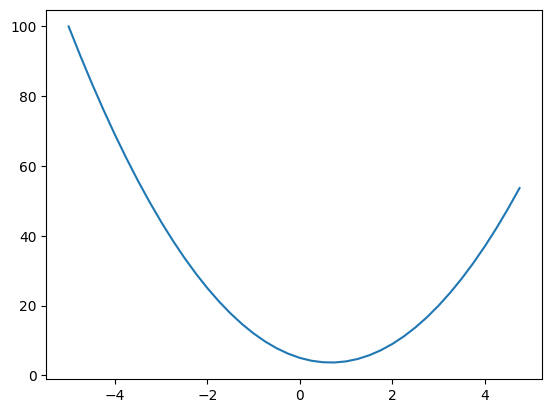

In [4]:
xs = np.arange(-5,5,0.25)
ys = f(xs)
plt.plot(xs,ys)

In [5]:
h = 0.0000001
x = 2/3
(f(x+h) - f(x))/h

2.9753977059954195e-07

In [6]:
h = 0.00001
#inputs
a = 2.00
b = -3.00
c = 4

d = a*b-c
print('d',d)
a += h
d1 = a*b-c
print('d1',d1)
print('slop', (d1-d)/h)


d -10.0
d1 -10.00003
slop -3.000000000064062


In [7]:
class Value:
  def __init__(self,data,_children = (),_op = '', label = ""):
    self.data = data
    self.grad = 0.0
    self._prev = set(_children)
    self._op = _op
    self.label = label
    self._backward = lambda: None

  def __repr__(self):
    return f'Value(data={self.data})'

  def __add__(self,other):
    other = other if isinstance(other, Value) else Value(other)
    out = Value(self.data + other.data, (self,other), '+' )

    def _backward():
      self.grad += 1.0 * out.grad
      other.grad += 1.0 * out.grad
    out._backward = _backward
    return out

  def __radd__(self,other):
    return self + other

  def __mul__(self,other):
    other = other if isinstance(other,Value) else Value(other)
    out = Value(self.data * other.data, (self,other),'*')
    def _backward():
      self.grad += other.data * out.grad
      other.grad += self.data * out.grad
    out._backward = _backward
    return out

  def __rmul__(self,other):
    return self * other

  def __pow__(self,other):
    assert isinstance(other, (int,float)), "only support int/float"
    out = Value(self.data**other, (self,), f'**{other}')
    def _backward():
      self.grad += other * self.data ** (other - 1) * out.grad
    out._backward = _backward
    return out

  def __truediv__(self,other):
    return self * other**-1

  def __neg__(self):
    return self * -1

  def __sub__(self,other):
    return self + (-other)

  def tanh(self):
    t = (math.exp(2*self.data) - 1)/(math.exp(2*self.data) + 1)
    out = Value(t, (self,), 'tanh')
    def _backward():
      self.grad += (1 - t**2) * out.grad
    out._backward = _backward
    return out

  def exp(self):
    out = Value(math.exp(self.data),(self,), 'exp')

    def _backward():
      self.grad += out.data * out.grad
    out._backward = _backward
    return out

  def backward(self):
    topo = []
    visited = set()

    def build_topo(v):
      if v not in visited:
        visited.add(v)
        for child in v._prev:
          build_topo(child)
        topo.append(v)
    build_topo(self)

    self.grad = 1.0
    for node in reversed(topo):
      node._backward()

a = Value(2.00, label = 'a')
b = Value(-3.00, label = 'b')
c = Value(4, label = 'c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2, label = 'f')
L = d * f; L.label = 'L'



In [8]:
a = 2.00
b = 4.00
a / b


0.5

In [9]:
from graphviz import Digraph

def trace(root):
    nodes, edges = set(), set()
    def build(v):
        if v not in nodes:
            nodes.add(v)
            for child in v._prev:
                edges.add((child, v))
                build(child)
    build(root)
    return nodes, edges

def draw_dot(root):
    dot = Digraph(format='svg', graph_attr={'rankdir': 'LR'})

    nodes, edges = trace(root)
    for n in nodes:
        uid = str(id(n))
        dot.node(name=uid, label="{ %s | data %.4f | grad %.4f }" % (n.label, n.data, n.grad), shape='record')
        if n._op:
            dot.node(name=uid + n._op, label=n._op)
            dot.edge(uid + n._op, uid)

    for n1, n2 in edges:
        dot.edge(str(id(n1)), str(id(n2)) + n2._op)

    return dot

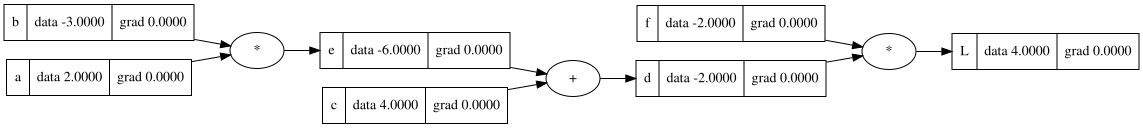

In [10]:
draw_dot(L)

In [11]:
a = Value(2.00, label = 'a')
b = Value(-3.00, label = 'b')
c = Value(4, label = 'c')
e = a*b; e.label = 'e'
d = e + c; d.label = 'd'
f = Value(-2, label = 'f')
L = d * f; L.label = 'L'

L.grad = 1.0
d.grad = f.data
f.grad = d.data
c.grad = d.grad
e.grad = d.grad
a.grad = b.data * e.grad
b.grad = a.data * e.grad

In [12]:
def lol():
  h = 0.0001
  a = Value(2.00, label = 'a')
  b = Value(-3.00, label = 'b')
  c = Value(4, label = 'c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2, label = 'f')
  L = d * f; L.label = 'L'
  L1 = L.data

  a = Value(2.00 + h, label = 'a')
  b = Value(-3.00, label = 'b')
  c = Value(4, label = 'c')
  e = a*b; e.label = 'e'
  d = e + c; d.label = 'd'
  f = Value(-2, label = 'f')
  L = d * f; L.label = 'L'
  L2 = L.data
  print((L2-L1)/h)
lol()


6.000000000021544


In [13]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2 ; x1w1x2w2.label = 'x1*w1x2*w2'
n = x1w1x2w2 + b; n.label = 'n'
o = n.tanh(); o.label = 'o'
o.backward()



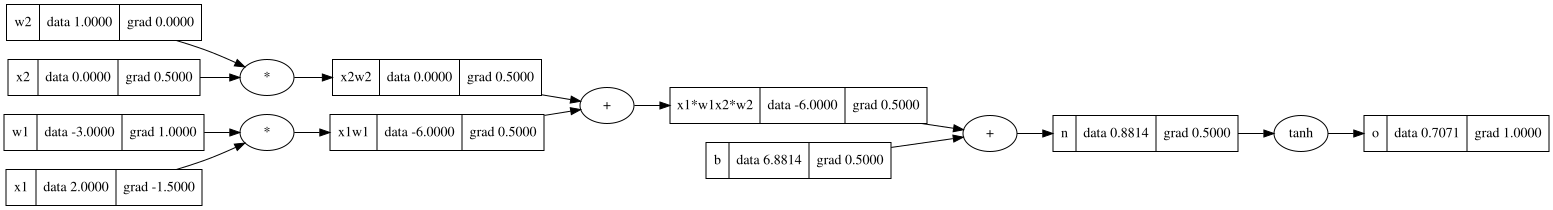

In [14]:
draw_dot(o)

In [15]:
x1 = Value(2.0, label='x1')
x2 = Value(0.0, label='x2')

w1 = Value(-3.0, label='w1')
w2 = Value(1.0, label='w2')
b = Value(6.8813735870195432, label='b')

x1w1 = x1*w1; x1w1.label = 'x1w1'
x2w2 = x2*w2; x2w2.label = 'x2w2'
x1w1x2w2 = x1w1 + x2w2 ; x1w1x2w2.label = 'x1*w1x2*w2'
n = x1w1x2w2 + b; n.label = 'n'

e = (2*n).exp()
o = (e - 1) / (e + 1)

o.backward()

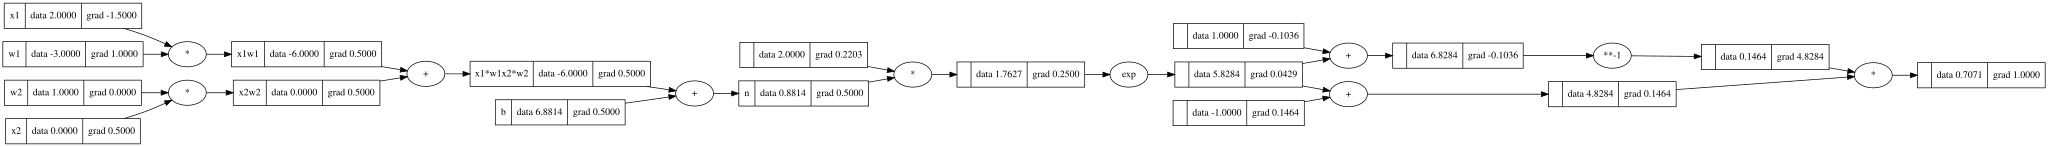

In [16]:
draw_dot(o)

In [17]:
import torch
x1 = torch.Tensor([2.0]).double() ;x1.requires_grad = True
x2 = torch.Tensor([0.0]).double() ;x2.requires_grad = True
w1 = torch.Tensor([-3.0]).double() ;w1.requires_grad = True
w2 = torch.Tensor([1.0]).double() ;w2.requires_grad = True

b = torch.Tensor([6.8813735870195432]).double() ;b.requires_grad = True
n = x1*w1 + x2*w2 + b

o = torch.tanh(n)
print(o.data.item())


o.backward()
print('---')
print('x2',x2.grad.item())
print('x1',x1.grad.item())
print('w2',w2.grad.item())
print('w1',w1.grad.item())



0.7071066904050358
---
x2 0.5000001283844369
x1 -1.5000003851533106
w2 0.0
w1 1.0000002567688737


In [18]:
class Neuron:
  def __init__(self, nin):
    self.w = [Value(random.uniform(-1,1)) for _ in range(nin)]
    self.b = Value(random.uniform(-1,1))

  def __call__(self,x):
    act = sum((wi*xi for wi,xi in zip(self.w,x)), self.b)
    out = act.tanh()
    return out

  def parameters(self):
    return self.w + [self.b]

class Layer:
  def __init__(self, nin, nout):
    self.neurons = [Neuron(nin) for _ in range(nout)]

  def __call__(self,x):
    outs = [n(x) for n in self.neurons]
    return outs[0] if len(outs) == 1 else outs

  def parameters(self):
    return [p for neuron in self.neurons for p in neuron.parameters()]

class MLP:
  def __init__(self,nin, nouts):
    size = [nin] + nouts
    self.layers = [Layer(size[i],size[i+1]) for i in range(len(size) - 1)]

  def __call__(self, x):
    for layer in self.layers:
        x = layer(x)
    return x

  def parameters(self):
    return [p for layer in self.layers for p in layer.parameters()]


x = [2,4,4]
n = MLP(3,[4,1])
n(x)

Value(data=-0.7412364073642504)

In [19]:
x = [2.0, 3.0, -1.0]
n = MLP(3, [4, 4, 1])

xs = [
  [2.0, 3.0, -1.0],
  [3.0, -1.0, 0.5],
  [0.5, 1.0, 1.0],
  [1.0, 1.0, -1.0],
]
ys = [1.0, -1.0, -1.0, 1.0]
ypred = [n(x) for x in xs]

In [20]:
loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))
loss

Value(data=6.547313303034657)

In [21]:
loss.backward()
n.layers[0].neurons[0].w[0].grad

-1.7293169794831105

In [22]:
for p in n.parameters():
  p.data += -.001*p.grad


In [23]:
for k in range(100):
  ypred = [n(x) for x in xs]
  loss = sum((yout - ygt)**2 for ygt, yout in zip(ys, ypred))

  for p in n.parameters():
    p.grad = 0.0
  loss.backward()

  for p in n.parameters():
    p.data += -.001*p.grad
  print(k,loss.data)

0 6.4921496395115845
1 6.435256972118351
2 6.376536230512512
3 6.315883943806155
4 6.253192018976316
5 6.1883475083586115
6 6.1212323694874335
7 6.051723223592191
8 5.979691123721275
9 5.905001350416583
10 5.827513263007246
11 5.747080249126423
12 5.663549835519527
13 5.576764051524297
14 5.486560175037038
15 5.392772041813692
16 5.295232164879361
17 5.19377499290176
18 5.088241733300664
19 4.978487271011222
20 4.864389811047095
21 4.745863930560516
22 4.6228776892164225
23 4.495474231255891
24 4.363797805536485
25 4.228123207230654
26 4.088886223620028
27 3.94671080233665
28 3.8024266842807597
29 3.6570698732369644
30 3.5118586073185556
31 3.3681404793471073
32 3.2273122967951178
33 3.0907219585227046
34 2.9595682790794884
35 2.834817113961052
36 2.717148649699452
37 2.6069424859902597
38 2.504297637898983
39 2.4090775331418435
40 2.320967399035707
41 2.23953274850924
42 2.164271215595897
43 2.094653892593432
44 2.030155408713646
45 1.9702738852788504
46 1.9145427481603225
47 1.862536

In [24]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import gzip, os, urllib.request
rng = np.random.default_rng(0)

In [25]:
def load_mnist():
    base = "https://ossci-datasets.s3.amazonaws.com/mnist/"
    names = ["train-images-idx3-ubyte.gz", "train-labels-idx1-ubyte.gz",
             "t10k-images-idx3-ubyte.gz", "t10k-labels-idx1-ubyte.gz"]
    os.makedirs("mnist_data", exist_ok=True)
    for n in names:
        if not os.path.exists("mnist_data/" + n):
            urllib.request.urlretrieve(base + n, "mnist_data/" + n)
    def read(n, offset):
        with gzip.open("mnist_data/" + n) as f:
            return np.frombuffer(f.read(), np.uint8, offset=offset)
    X_tr = read(names[0], 16).reshape(-1, 1, 28, 28) / 255.0
    y_tr = read(names[1], 8)
    X_te = read(names[2], 16).reshape(-1, 1, 28, 28) / 255.0
    y_te = read(names[3], 8)
    return X_tr, y_tr, X_te, y_te

X_all, y_all, X_test, y_test = load_mnist()


p = rng.permutation(len(X_all))
X_all, y_all = X_all[p], y_all[p]
X_train, y_train = X_all[:55000], y_all[:55000]
X_val, y_val = X_all[55000:], y_all[55000:]
print(X_train.shape, X_val.shape, X_test.shape)

(55000, 1, 28, 28) (5000, 1, 28, 28) (10000, 1, 28, 28)


In [26]:
mean, std = 0.1307, 0.3081
X_train = (X_train - mean) / std
X_val   = (X_val   - mean) / std
X_test  = (X_test  - mean) / std

In [27]:
class Conv:
    def __init__(self, in_ch, out_ch, k=3):
        self.k = k
        self.W = rng.standard_normal((out_ch, in_ch, k, k)) * np.sqrt(2 / (in_ch * k * k))
        self.b = np.zeros(out_ch)

    def forward(self, x):
        self.x = x
        k = self.k
        oh, ow = x.shape[2] - k + 1, x.shape[3] - k + 1
        out = np.zeros((x.shape[0], self.W.shape[0], oh, ow)) + self.b[None, :, None, None]
        for i in range(k):
            for j in range(k):
                patch = x[:, :, i:i+oh, j:j+ow]
                out += np.einsum('ncxy,fc->nfxy', patch, self.W[:, :, i, j])
        return out

    def backward(self, dout):
        k = self.k
        oh, ow = dout.shape[2], dout.shape[3]
        self.dW = np.zeros_like(self.W)
        dx = np.zeros_like(self.x)
        for i in range(k):
            for j in range(k):
                patch = self.x[:, :, i:i+oh, j:j+ow]
                self.dW[:, :, i, j] = np.einsum('nfxy,ncxy->fc', dout, patch)
                dx[:, :, i:i+oh, j:j+ow] += np.einsum('nfxy,fc->ncxy', dout, self.W[:, :, i, j])
        self.db = dout.sum(axis=(0, 2, 3))
        return dx

class ReLU:
    def forward(self, x):
        self.mask = x > 0
        return x * self.mask
    def backward(self, dout):
        return dout * self.mask

class MaxPool:
    def forward(self, x):
        N, C, H, W = x.shape
        self.shape = x.shape
        xr = x.reshape(N, C, H // 2, 2, W // 2, 2)
        out = xr.max(axis=(3, 5))
        self.mask = xr == out[:, :, :, None, :, None]
        return out
    def backward(self, dout):
        d = self.mask * dout[:, :, :, None, :, None]
        return d.reshape(self.shape)

class Dense:
    def __init__(self, nin, nout):
        self.W = rng.standard_normal((nin, nout)) * np.sqrt(2 / nin)
        self.b = np.zeros(nout)
    def forward(self, x):
        self.x = x.reshape(x.shape[0], -1)
        self.in_shape = x.shape
        return self.x @ self.W + self.b
    def backward(self, dout):
        self.dW = self.x.T @ dout
        self.db = dout.sum(axis=0)
        return (dout @ self.W.T).reshape(self.in_shape)

In [28]:
def softmax_loss(logits, y):
    z = np.exp(logits - logits.max(axis=1, keepdims=True))
    probs = z / z.sum(axis=1, keepdims=True)
    n = len(y)
    loss = -np.log(probs[np.arange(n), y] + 1e-12).mean()
    grad = probs.copy()
    grad[np.arange(n), y] -= 1
    return loss, grad / n

class CNN:
    def __init__(self):
        self.conv = Conv(1, 8)
        self.relu = ReLU()
        self.pool = MaxPool()
        self.fc = Dense(8 * 13 * 13, 10)
        self.layers = [self.conv, self.relu, self.pool, self.fc]

    def forward(self, x):
        for layer in self.layers:
            x = layer.forward(x)
        return x

    def backward(self, d):
        for layer in reversed(self.layers):
            d = layer.backward(d)

    def update(self, lr):
        for layer in (self.conv, self.fc):
            layer.W -= lr * layer.dW
            layer.b -= lr * layer.db

In [29]:
def accuracy(model, X, y):
    preds = np.concatenate([model.forward(X[i:i+500]).argmax(1) for i in range(0, len(X), 500)])
    return (preds == y).mean()

model = CNN()
N_TRAIN = 55000     
EPOCHS, BATCH, LR = 8, 64, 0.02
rows = []

for epoch in range(EPOCHS):
    idx = rng.permutation(N_TRAIN)
    losses = []
    for i in range(0, N_TRAIN, BATCH):
        b = idx[i:i+BATCH]
        logits = model.forward(X_train[b])
        loss, grad = softmax_loss(logits, y_train[b])
        model.backward(grad)
        model.update(LR)
        losses.append(loss)
    rows.append({"epoch": epoch + 1,
                 "train_loss": np.mean(losses),
                 "val_acc": accuracy(model, X_val, y_val)})
    print(rows[-1])

history = pd.DataFrame(rows)
history

{'epoch': 1, 'train_loss': np.float64(0.35293176162174167), 'val_acc': np.float64(0.939)}
{'epoch': 2, 'train_loss': np.float64(0.1695454817235487), 'val_acc': np.float64(0.9526)}
{'epoch': 3, 'train_loss': np.float64(0.125551101904555), 'val_acc': np.float64(0.9494)}
{'epoch': 4, 'train_loss': np.float64(0.10309515751416873), 'val_acc': np.float64(0.968)}
{'epoch': 5, 'train_loss': np.float64(0.0896564298814418), 'val_acc': np.float64(0.9682)}
{'epoch': 6, 'train_loss': np.float64(0.08025029599416217), 'val_acc': np.float64(0.9688)}
{'epoch': 7, 'train_loss': np.float64(0.07276929053668105), 'val_acc': np.float64(0.9718)}
{'epoch': 8, 'train_loss': np.float64(0.06768717086696788), 'val_acc': np.float64(0.9714)}


,epoch,train_loss,val_acc
0,1,0.352932,0.9390
1,2,0.169545,0.9526
2,3,0.125551,0.9494
3,4,0.103095,0.9680
4,5,0.089656,0.9682
5,6,0.080250,0.9688
6,7,0.072769,0.9718
7,8,0.067687,0.9714


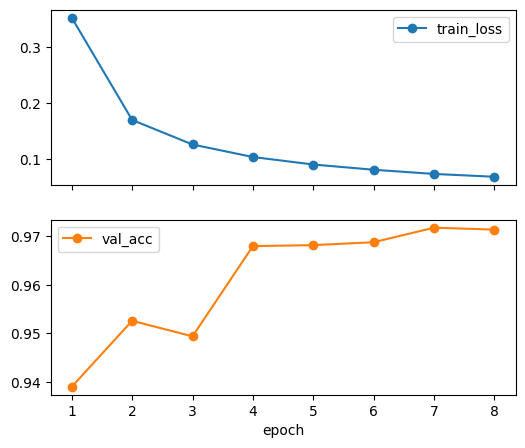

In [30]:
history.plot(x="epoch", y=["train_loss", "val_acc"], subplots=True, marker="o", figsize=(6, 5))
plt.show()

In [31]:
test_acc = accuracy(model, X_test, y_test)
print("TEST accuracy:", test_acc)

preds = np.concatenate([model.forward(X_test[i:i+500]).argmax(1) for i in range(0, len(X_test), 500)])
results = pd.DataFrame({"true": y_test, "pred": preds})
results["correct"] = results.true == results.pred

print(results.groupby("true").correct.mean().round(3).rename("accuracy per digit"))
pd.crosstab(results.true, results.pred)

TEST accuracy: 0.9744
true
0    0.994
1    0.996
2    0.968
3    0.982
4    0.976
5    0.987
6    0.973
7    0.949
8    0.968
9    0.951
Name: accuracy per digit, dtype: float64


pred,0,1,2,3,4,5,6,7,8,9
true,,,,,,,,,,
0,974,0,2,0,0,1,1,1,1,0
1,0,1130,2,1,0,1,0,0,1,0
2,3,13,999,5,2,0,3,6,1,0
3,1,0,2,992,0,8,0,3,4,0
4,1,2,0,0,958,0,4,1,2,14
5,2,0,0,5,0,880,4,0,1,0
6,9,4,0,0,3,10,932,0,0,0
7,0,6,12,15,2,1,0,976,5,11
8,8,0,4,4,3,4,0,3,943,5


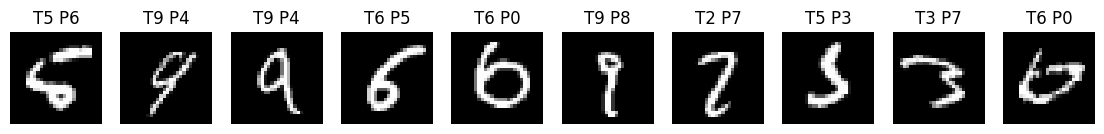

In [32]:
wrong = results[~results.correct].index[:10]
fig, ax = plt.subplots(1, 10, figsize=(14, 2))
for a, i in zip(ax, wrong):
    a.imshow(X_test[i, 0], cmap="gray")
    a.set_title(f"T{y_test[i]} P{preds[i]}")
    a.axis("off")
plt.show()

In [33]:
x = rng.standard_normal((3, 1, 28, 28)); y = np.array([1, 2, 3])
m = CNN()
loss, g = softmax_loss(m.forward(x), y); m.backward(g)
h = 1e-5
for name, W, dW in [("conv", m.conv.W, m.conv.dW), ("dense", m.fc.W, m.fc.dW)]:
    idx = tuple(rng.integers(0, s) for s in W.shape)
    old = W[idx]
    W[idx] = old + h; lp, _ = softmax_loss(m.forward(x), y)
    W[idx] = old - h; lm, _ = softmax_loss(m.forward(x), y)
    W[idx] = old
    print(name, "numerical:", (lp - lm) / (2 * h), "backprop:", dW[idx])

conv numerical: 0.005461257535088747 backprop: 0.005461257615298587
dense numerical: 0.048156477649996525 backprop: 0.04815647765399393


In [34]:
import torch, torch.nn as nn, time

np_history, np_test_acc = history.copy(), test_acc

torch.manual_seed(0)
Xtr_t, ytr_t = torch.tensor(X_train, dtype=torch.float32), torch.tensor(y_train, dtype=torch.long)
Xva_t, yva_t = torch.tensor(X_val, dtype=torch.float32), torch.tensor(y_val, dtype=torch.long)
Xte_t, yte_t = torch.tensor(X_test, dtype=torch.float32), torch.tensor(y_test, dtype=torch.long)

In [35]:

torch_model = nn.Sequential(
    nn.Conv2d(1, 8, 3),      
    nn.ReLU(),
    nn.MaxPool2d(2),         
    nn.Flatten(),
    nn.Linear(8 * 13 * 13, 10),
)
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.SGD(torch_model.parameters(), lr=0.02)  

def torch_accuracy(X, y):
    torch_model.eval()
    with torch.no_grad():
        return (torch_model(X).argmax(1) == y).float().mean().item()

In [36]:
rows = []
t0 = time.time()
for epoch in range(EPOCHS):
    torch_model.train()
    idx = torch.randperm(N_TRAIN)
    losses = []
    for i in range(0, N_TRAIN, BATCH):
        b = idx[i:i+BATCH]
        loss = loss_fn(torch_model(Xtr_t[b]), ytr_t[b])
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        losses.append(loss.item())
    rows.append({"epoch": epoch + 1,
                 "train_loss": np.mean(losses),
                 "val_acc": torch_accuracy(Xva_t, yva_t)})
    print(rows[-1])
torch_time = time.time() - t0

torch_history = pd.DataFrame(rows)
torch_test_acc = torch_accuracy(Xte_t, yte_t)
print("PyTorch TEST accuracy:", torch_test_acc, f"({torch_time:.0f}s)")

{'epoch': 1, 'train_loss': np.float64(0.3742398995732845), 'val_acc': 0.9154000282287598}
{'epoch': 2, 'train_loss': np.float64(0.2124445984226673), 'val_acc': 0.9332000017166138}
{'epoch': 3, 'train_loss': np.float64(0.1578506809421057), 'val_acc': 0.9503999948501587}
{'epoch': 4, 'train_loss': np.float64(0.12538435814880527), 'val_acc': 0.9595999717712402}
{'epoch': 5, 'train_loss': np.float64(0.10561564944922751), 'val_acc': 0.9649999737739563}
{'epoch': 6, 'train_loss': np.float64(0.09147491106373626), 'val_acc': 0.9646000266075134}
{'epoch': 7, 'train_loss': np.float64(0.0818462563212961), 'val_acc': 0.9706000089645386}
{'epoch': 8, 'train_loss': np.float64(0.07444517883407169), 'val_acc': 0.9724000096321106}
PyTorch TEST accuracy: 0.9760000109672546 (27s)


 epoch  numpy_loss  torch_loss  numpy_val_acc  torch_val_acc
     1      0.3529      0.3742         0.9390         0.9154
     2      0.1695      0.2124         0.9526         0.9332
     3      0.1256      0.1579         0.9494         0.9504
     4      0.1031      0.1254         0.9680         0.9596
     5      0.0897      0.1056         0.9682         0.9650
     6      0.0803      0.0915         0.9688         0.9646
     7      0.0728      0.0818         0.9718         0.9706
     8      0.0677      0.0744         0.9714         0.9724

TEST accuracy -> NumPy: 0.9744 | PyTorch: 0.9760


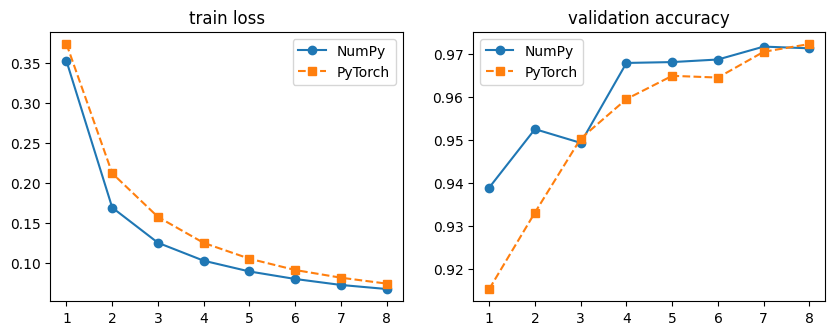

In [37]:
compare = pd.DataFrame({
    "epoch": np_history.epoch,
    "numpy_loss": np_history.train_loss, "torch_loss": torch_history.train_loss,
    "numpy_val_acc": np_history.val_acc, "torch_val_acc": torch_history.val_acc,
})
print(compare.round(4).to_string(index=False))
print(f"\nTEST accuracy -> NumPy: {np_test_acc:.4f} | PyTorch: {torch_test_acc:.4f}")

fig, ax = plt.subplots(1, 2, figsize=(10, 3.5))
ax[0].plot(compare.epoch, compare.numpy_loss, "o-", label="NumPy")
ax[0].plot(compare.epoch, compare.torch_loss, "s--", label="PyTorch"); ax[0].set_title("train loss"); ax[0].legend()
ax[1].plot(compare.epoch, compare.numpy_val_acc, "o-", label="NumPy")
ax[1].plot(compare.epoch, compare.torch_val_acc, "s--", label="PyTorch"); ax[1].set_title("validation accuracy"); ax[1].legend()
plt.show()